In [1]:
import torch
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from lurssen.models.unet import ConditionalUNet
from lurssen.models.diff import ConditionalDDPM 
from lurssen.dataset import get_dataloader
from lurssen.encoder import RoomGenEncoder


epochs = 200

device = "cuda" if torch.cuda.is_available() else "cpu"

model = ConditionalUNet(
    in_channels=3,
    cond_channels=64,
).to(device)

diffusion = ConditionalDDPM(
    model,
    timesteps=1000,
    beta_start=1e-4,
    beta_end=0.02,
    device=device
)

encoder = RoomGenEncoder().to(device)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(encoder.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

train_loader = get_dataloader(num_samples=1, batch_size=1, seed=41)
print(len(train_loader))

/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


1


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


tensor(-1.) tensor(1.)
tensor(0.) tensor(1.)
tensor(0.0580) tensor(0.4605)
tensor(0) tensor(4)


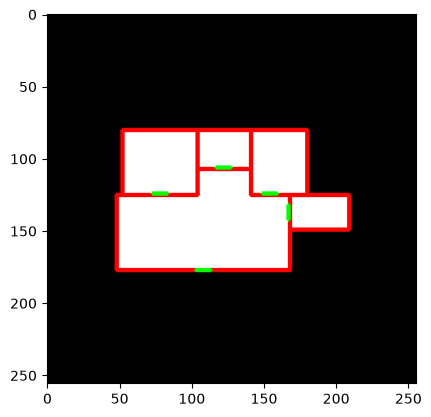

In [2]:
floorplan, outershell_mask, node_features, edge_features = next(iter(train_loader))
plt.imshow(floorplan.squeeze(0).permute(2,1,0))
print(min(floorplan.flatten()), max(floorplan.flatten()))
print(min(outershell_mask.flatten()), max(outershell_mask.flatten()))
print(min(node_features[0].flatten()), max(node_features[0].flatten()))
print(min(edge_features[0].flatten()), max(edge_features[0].flatten()))

In [3]:
train_losses = []
for epoch in range(epochs):
    model.train()
    encoder.train()
    total_loss = 0.0
    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch [{epoch + 1}/{epochs}]",
        leave=True
    )
    for floorplan, outershell_mask, node_features, edge_features in progress_bar:
        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)
        node_features = [x.to(device) for x in node_features]
        edge_features = [x.to(device) for x in edge_features]

        # TODO: Multiple batches
        condition = encoder(
            outershell_mask,
            node_features[0],
            edge_features[0]
        )

        condition = condition.to(device)
        loss = diffusion.loss(
            floorplan,
            condition
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.6f}"
    )
    
torch.save(encoder.state_dict(), "encoder.pt")
torch.save(model.state_dict(), "model.pt")

Epoch [1/200]: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s]


Epoch [1/200] Loss: 1.131173


Epoch [2/200]: 100%|██████████| 1/1 [00:00<00:00,  2.30it/s]


Epoch [2/200] Loss: 1.069920


Epoch [3/200]: 100%|██████████| 1/1 [00:00<00:00,  2.14it/s]


Epoch [3/200] Loss: 1.015409


... (390 outputs left out)

Epoch [199/200]: 100%|██████████| 1/1 [00:00<00:00,  2.12it/s]


Epoch [199/200] Loss: 0.101266


Epoch [200/200]: 100%|██████████| 1/1 [00:00<00:00,  2.17it/s]


Epoch [200/200] Loss: 0.095470


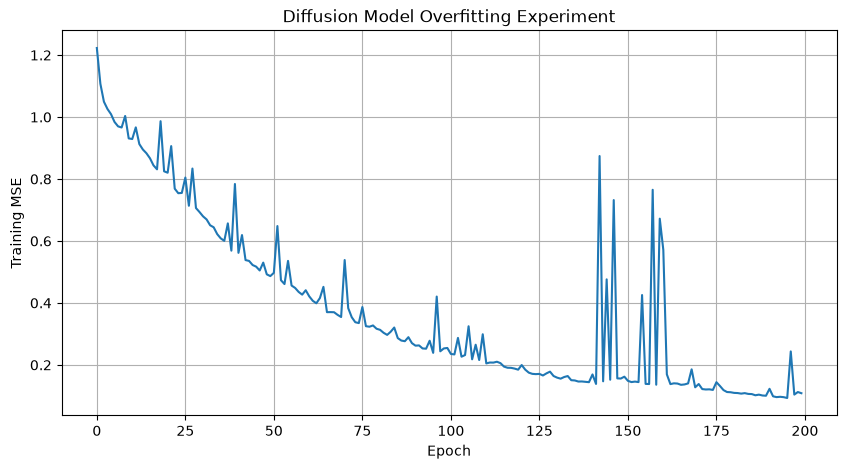

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Diffusion Model Overfitting Experiment")

plt.grid()
plt.show()

In [ ]:
#state_dict = torch.load("model.pth", map_location="cuda", weights_only=True)
#model.load_state_dict(state_dict)

t=999 | x_mean=0.0008 | x_std=1.0001 | pred_mean=0.0000 | pred_std=0.8678 | pred_min=-3.7256 | pred_max=4.0990
t=998 | x_mean=0.0009 | x_std=1.0034 | pred_mean=0.0039 | pred_std=0.8667 | pred_min=-3.8020 | pred_max=4.0324
t=997 | x_mean=0.0006 | x_std=1.0066 | pred_mean=0.0075 | pred_std=0.8652 | pred_min=-3.8106 | pred_max=4.0512
t=996 | x_mean=0.0001 | x_std=1.0101 | pred_mean=0.0086 | pred_std=0.8634 | pred_min=-3.9402 | pred_max=4.0351
t=995 | x_mean=0.0001 | x_std=1.0136 | pred_mean=0.0071 | pred_std=0.8621 | pred_min=-4.0985 | pred_max=3.9960
t=994 | x_mean=-0.0006 | x_std=1.0176 | pred_mean=0.0036 | pred_std=0.8611 | pred_min=-3.9213 | pred_max=3.8860
t=993 | x_mean=-0.0011 | x_std=1.0218 | pred_mean=0.0002 | pred_std=0.8606 | pred_min=-3.8843 | pred_max=4.0364
t=992 | x_mean=-0.0009 | x_std=1.0254 | pred_mean=-0.0014 | pred_std=0.8598 | pred_min=-3.7888 | pred_max=4.0272
t=991 | x_mean=-0.0016 | x_std=1.0289 | pred_mean=-0.0026 | pred_std=0.8583 | pred_min=-3.9127 | pred_max=3.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-385.82446..290.82834].


tensor(-385.8245, device='cuda:0') tensor(290.8283, device='cuda:0')


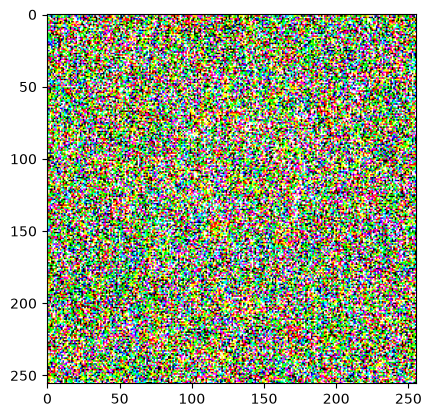

In [5]:

model.eval()
encoder.eval()

it = iter(train_loader)
for _ in range(len(train_loader)):
    floorplan, outershell_mask, node_features, edge_features = next(it)

    # Add batch dimension
    img = floorplan.unsqueeze(0).to(device)
    house_mask = outershell_mask.unsqueeze(0).to(device)
    with torch.no_grad():
        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)
        node_features = [x.to(device) for x in node_features]
        edge_features = [x.to(device) for x in edge_features]

        condition = encoder(
            outershell_mask,
            node_features[0],
            edge_features[0]
        )
        generated_floorplan = diffusion.sample(
            condition,
            image_size=256,
            channels=3
        )
        print(min(generated_floorplan.flatten()), max(generated_floorplan.flatten()))
        plt.imshow(generated_floorplan.cpu().squeeze().permute(1,2,0))
        plt.show()